In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from sklearn.preprocessing import RobustScaler

This is the historical data that covers sales from 2010-02-05 to 2012-11-01, in the file Walmart_Store_sales. Within this file you will find the following fields:\

Store - the store number
Date - the week of sales
Weekly_Sales - sales for the given store
Holiday_Flag - whether the week is a special holiday week 1 – Holiday week 0 – Non-holiday week
Temperature - Temperature on the day of sale
Fuel_Price - Cost of fuel in the region
CPI – Prevailing consumer price index
Unemployment - Prevailing unemployment rate
Holiday Events<br /> Super Bowl: 12-Feb-10, 11-Feb-11, 10-Feb-12, 8-Feb-13<br /> Labour Day: 10-Sep-10, 9-Sep-11, 7-Sep-12, 6-Sep-13<br /> Thanksgiving: 26-Nov-10, 25-Nov-11, 23-Nov-12, 29-Nov-13<br /> Christmas: 31-Dec-10, 30-Dec-11, 28-Dec-12, 27-Dec-13

In [2]:
df = pd.read_csv("Walmart.csv")

print("Размер:", df.shape)
display(df.head())
display(df.dtypes.to_frame("dtype"))
display(df.isna().sum().to_frame("missing"))
print("Полные дубликаты:", df.duplicated().sum())
print("Число магазинов:", df["Store"].nunique())

Размер: (6435, 8)


,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,05-02-2010,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,12-02-2010,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,19-02-2010,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,26-02-2010,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,05-03-2010,1554806.68,0,46.50,2.625,211.350143,8.106


,dtype
Store,int64
Date,str
Weekly_Sales,float64
Holiday_Flag,int64
Temperature,float64
Fuel_Price,float64
CPI,float64
Unemployment,float64


,missing
Store,0
Date,0
Weekly_Sales,0
Holiday_Flag,0
Temperature,0
Fuel_Price,0
CPI,0
Unemployment,0


Полные дубликаты: 0
Число магазинов: 45


Заполнение пропусков:
судя по анализу, данные без пропусков

In [3]:
missing = df.isnull().sum()

print("Количество пропусков по столбцам:")
print(missing)

if missing.sum() == 0:
    print("Пропуски отсутствуют, заполнение не требуется.")

Количество пропусков по столбцам:
Store           0
Date            0
Weekly_Sales    0
Holiday_Flag    0
Temperature     0
Fuel_Price      0
CPI             0
Unemployment    0
dtype: int64
Пропуски отсутствуют, заполнение не требуется.


Форматирование типов данных

In [4]:
df = df.drop_duplicates().copy()

df["Date"] = pd.to_datetime(df["Date"], format="%d-%m-%Y", errors="raise")
df["Store"] = df["Store"].astype("int16")
df["Holiday_Flag"] = pd.to_numeric(df["Holiday_Flag"], errors="raise").astype("int8")

numeric_cols = ["Weekly_Sales", "Temperature", "Fuel_Price", "CPI", "Unemployment"]
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="raise")

df = df.sort_values(["Store", "Date"]).reset_index(drop=True)
assert df["Date"].notna().all()
assert set(df["Holiday_Flag"].unique()).issubset({0, 1})
display(df.dtypes.to_frame("dtype"))

,dtype
Store,int16
Date,datetime64[us]
Weekly_Sales,float64
Holiday_Flag,int8
Temperature,float64
Fuel_Price,float64
CPI,float64
Unemployment,float64


Разделение датасета для обучения

рано, сначала надо данные обработать, уже потом делить на группы, с учетео не допуска утечки

In [5]:
# по дате, чтобы не показать будущее на тренировке
unique_dates = np.sort(df["Date"].unique())
cutoff_idx = int(len(unique_dates) * 0.80)
cutoff_date = pd.Timestamp(unique_dates[cutoff_idx])

train_mask = df["Date"] < cutoff_date
train_raw = df.loc[train_mask].copy()
test_raw = df.loc[~train_mask].copy()

print("Дата начала теста:", cutoff_date.date())
print("Train:", train_raw.shape, "| Test:", test_raw.shape)
print("Диапазон train:", train_raw.Date.min().date(), "—", train_raw.Date.max().date())
print("Диапазон test:", test_raw.Date.min().date(), "—", test_raw.Date.max().date())

Дата начала теста: 2012-04-13
Train: (5130, 8) | Test: (1305, 8)
Диапазон train: 2010-02-05 — 2012-04-06
Диапазон test: 2012-04-13 — 2012-10-26


Удаление выбросов

распределение по остальным посмотреть, добавить дргие праздники, пасха тем еще есть

Всего наблюдений: 6435
Потенциальных выбросов: 304 (4.72%)
Магазинов: 45
Дат: 143
Границы IQR посчитаны на train_raw (5130 строк)


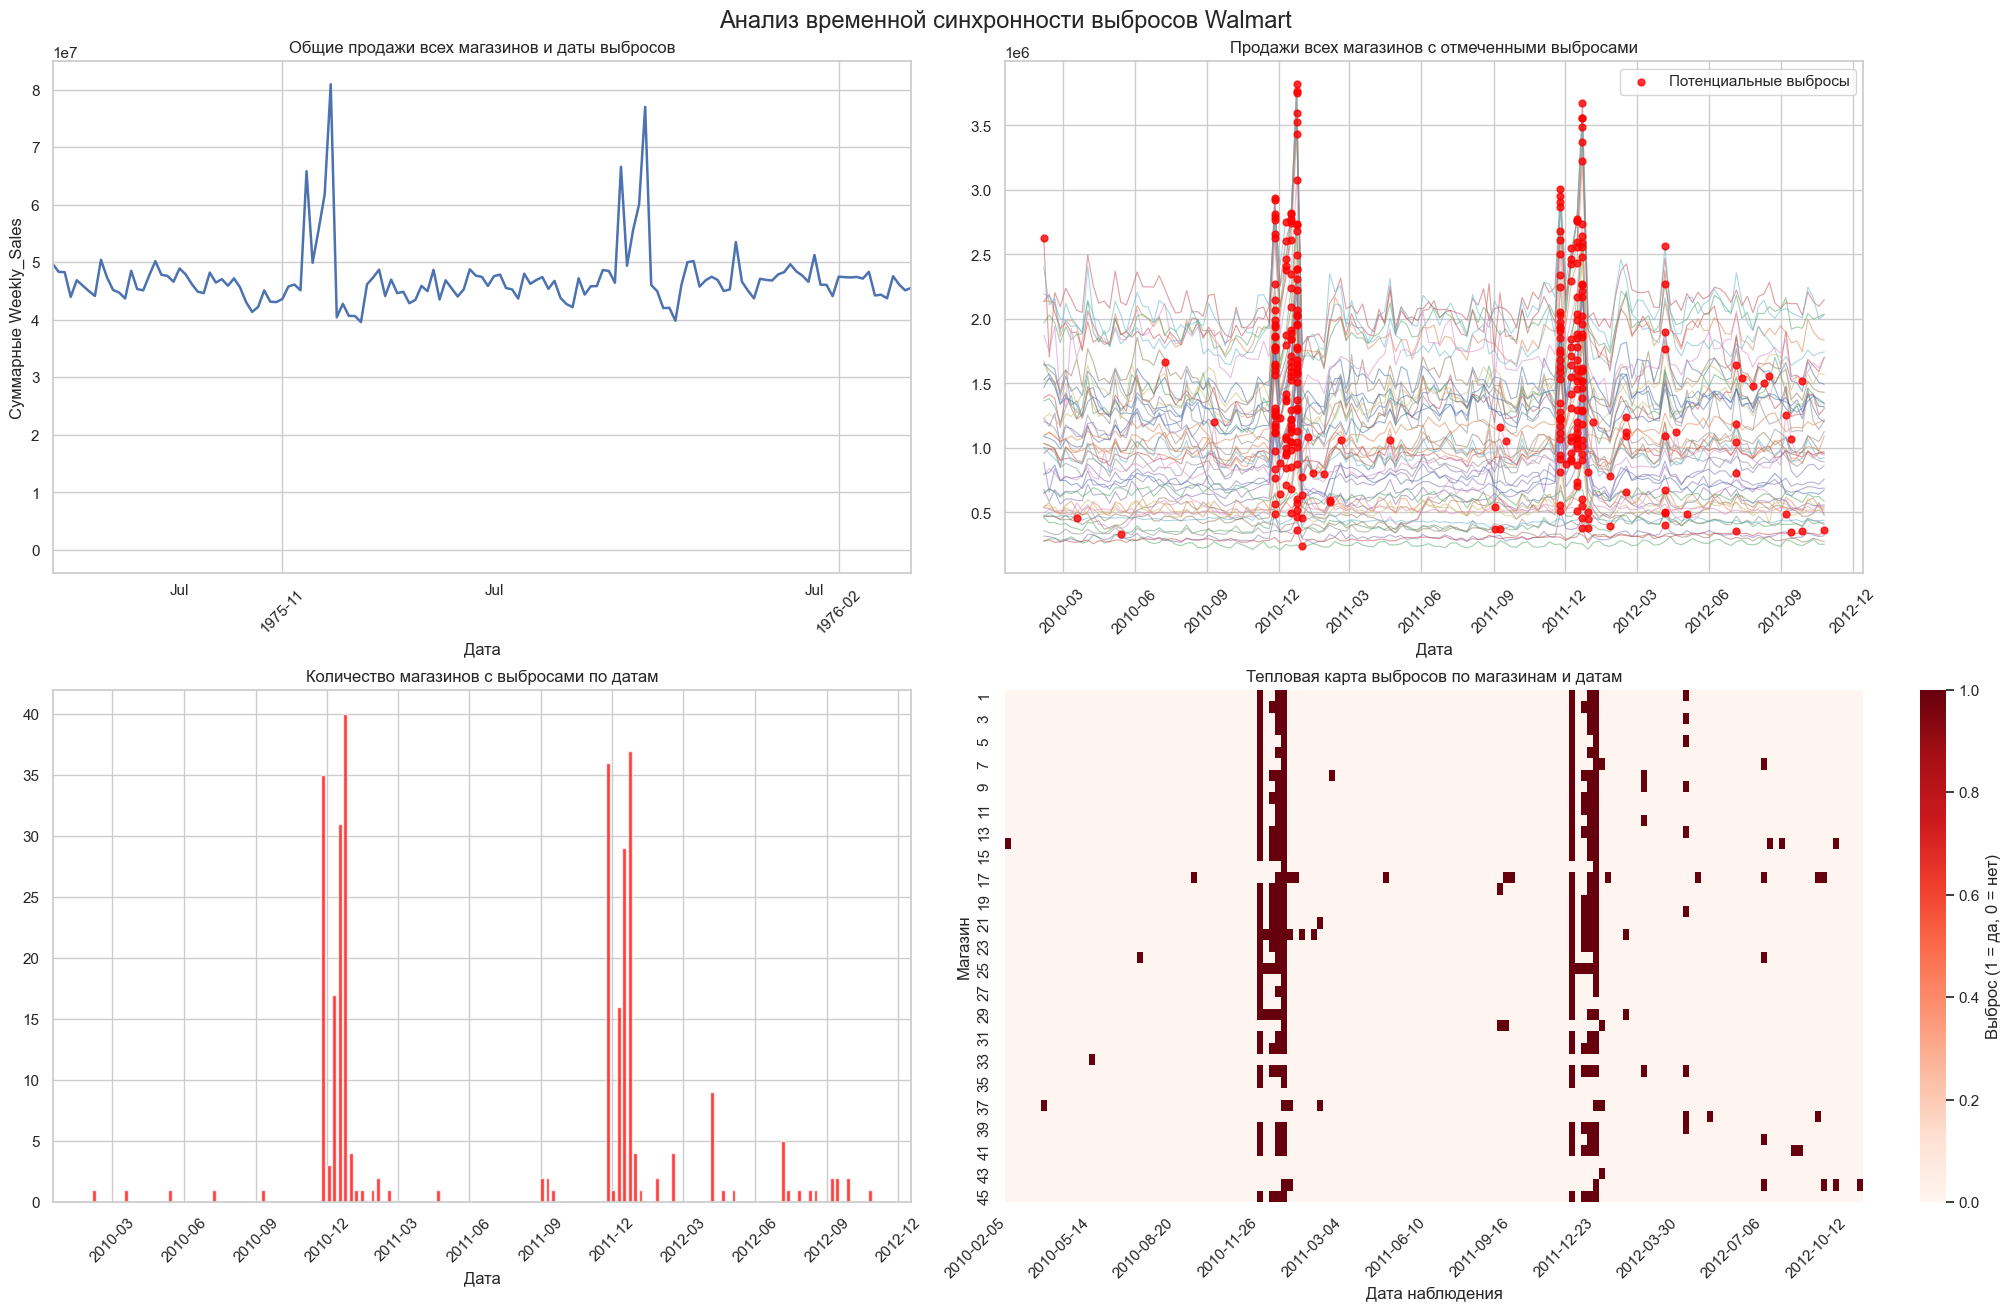

In [6]:
df_check = df.copy()
df_check['Date'] = pd.to_datetime(df_check['Date'], format='%d-%m-%Y')
df_check['Weekly_Sales'] = pd.to_numeric(df_check['Weekly_Sales'], errors='coerce')

# Расчёт границ IQR ТОЛЬКО на train_raw для каждого магазина
stats = train_raw.groupby('Store')['Weekly_Sales'].agg(
    Q1=lambda x: x.quantile(0.25),
    Q3=lambda x: x.quantile(0.75)
)
stats['IQR'] = stats['Q3'] - stats['Q1']
stats['Lower'], stats['Upper'] = stats['Q1'] - 1.5 * stats['IQR'], stats['Q3'] + 1.5 * stats['IQR']

df_check = df_check.join(stats[['Lower', 'Upper']], on='Store')

# Разметка выбросов
df_check['IQR_Outlier'] = (df_check['Weekly_Sales'] < df_check['Lower']) | (df_check['Weekly_Sales'] > df_check['Upper'])
df_check['Outlier_Type'] = np.select(
    [df_check['Weekly_Sales'] < df_check['Lower'], df_check['Weekly_Sales'] > df_check['Upper']],
    ['Нижний', 'Верхний'], default='Нет'
)
outliers = df_check[df_check['IQR_Outlier']].copy()


print(
    f"Всего наблюдений: {len(df_check)}\n"
    f"Потенциальных выбросов: {len(outliers)} ({len(outliers) / len(df_check) * 100:.2f}%)\n"
    f"Магазинов: {df_check['Store'].nunique()}\n"
    f"Дат: {df_check['Date'].nunique()}\n"
    f"Границы IQR посчитаны на train_raw ({len(train_raw)} строк)"
)


sns.set_theme(style='whitegrid')
fig, axes = plt.subplots(2, 2, figsize=(20, 13), constrained_layout=True)
ax1, ax2, ax3, ax4 = axes.flatten()

# График 1: Общие продажи и даты выбросов
total_sales = df_check.groupby('Date')['Weekly_Sales'].sum().sort_index()
total_sales.plot(ax=ax1, linewidth=1.8)
ax1.vlines(outliers['Date'].unique(), ymin=0, ymax=total_sales.max(), color='red', alpha=0.12, linewidth=0.8)
ax1.set_title('Общие продажи всех магазинов и даты выбросов')
ax1.set_ylabel('Суммарные Weekly_Sales')

# График 2: Продажи магазинов + выбросы
for _, group in df_check.groupby('Store'):
    ax2.plot(group['Date'], group['Weekly_Sales'], linewidth=0.8, alpha=0.55)
ax2.scatter(outliers['Date'], outliers['Weekly_Sales'], color='red', s=24, alpha=0.8, label='Потенциальные выбросы', zorder=5)
ax2.set_title('Продажи всех магазинов с отмеченными выбросами')
ax2.legend()

# График 3: Количество магазинов с выбросами по датам
outliers_per_date = outliers.groupby('Date')['Store'].nunique().sort_index()
ax3.bar(outliers_per_date.index, outliers_per_date.values, width=5, color='red', alpha=0.75)
ax3.set_title('Количество магазинов с выбросами по датам')

# График 4: Тепловая карта
heatmap_data = df_check.pivot_table(index='Store', columns='Date', values='IQR_Outlier', aggfunc='max', fill_value=False).astype(int)
sns.heatmap(heatmap_data, cmap='Reds', cbar_kws={'label': 'Выброс (1 = да, 0 = нет)'}, ax=ax4)
ax4.set_title('Тепловая карта выбросов по магазинам и датам')

# Унифицированное форматирование осей для всех графиков
for ax in (ax1, ax2, ax3, ax4):
    ax.set_xlabel('Дата')
    if ax != ax4:
        ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
        ax.tick_params(axis='x', rotation=45)
    else:
        # Для heatmap
        ax.set_xlabel('Дата наблюдения')
        ax.set_ylabel('Магазин')
        n_dates = len(heatmap_data.columns)
        step = max(1, n_dates // 10)
        ax.set_xticks(np.arange(0, n_dates, step) + 0.5)
        ax.set_xticklabels(
            [heatmap_data.columns[i].strftime('%Y-%m-%d') for i in range(0, n_dates, step)],
            rotation=45, ha='right'
        )

fig.suptitle('Анализ временной синхронности выбросов Walmart', fontsize=17)
plt.show()

скорее всего в праздники происходит пик продаж, это надо учесть

Наблюдений в праздничных периодах: 2205
Выбросов всего: 304
Выбросов в праздничных периодах: 277
Обычные потенциальные выбросы: 27
Праздничные пики, исключённые из выбросов: 277



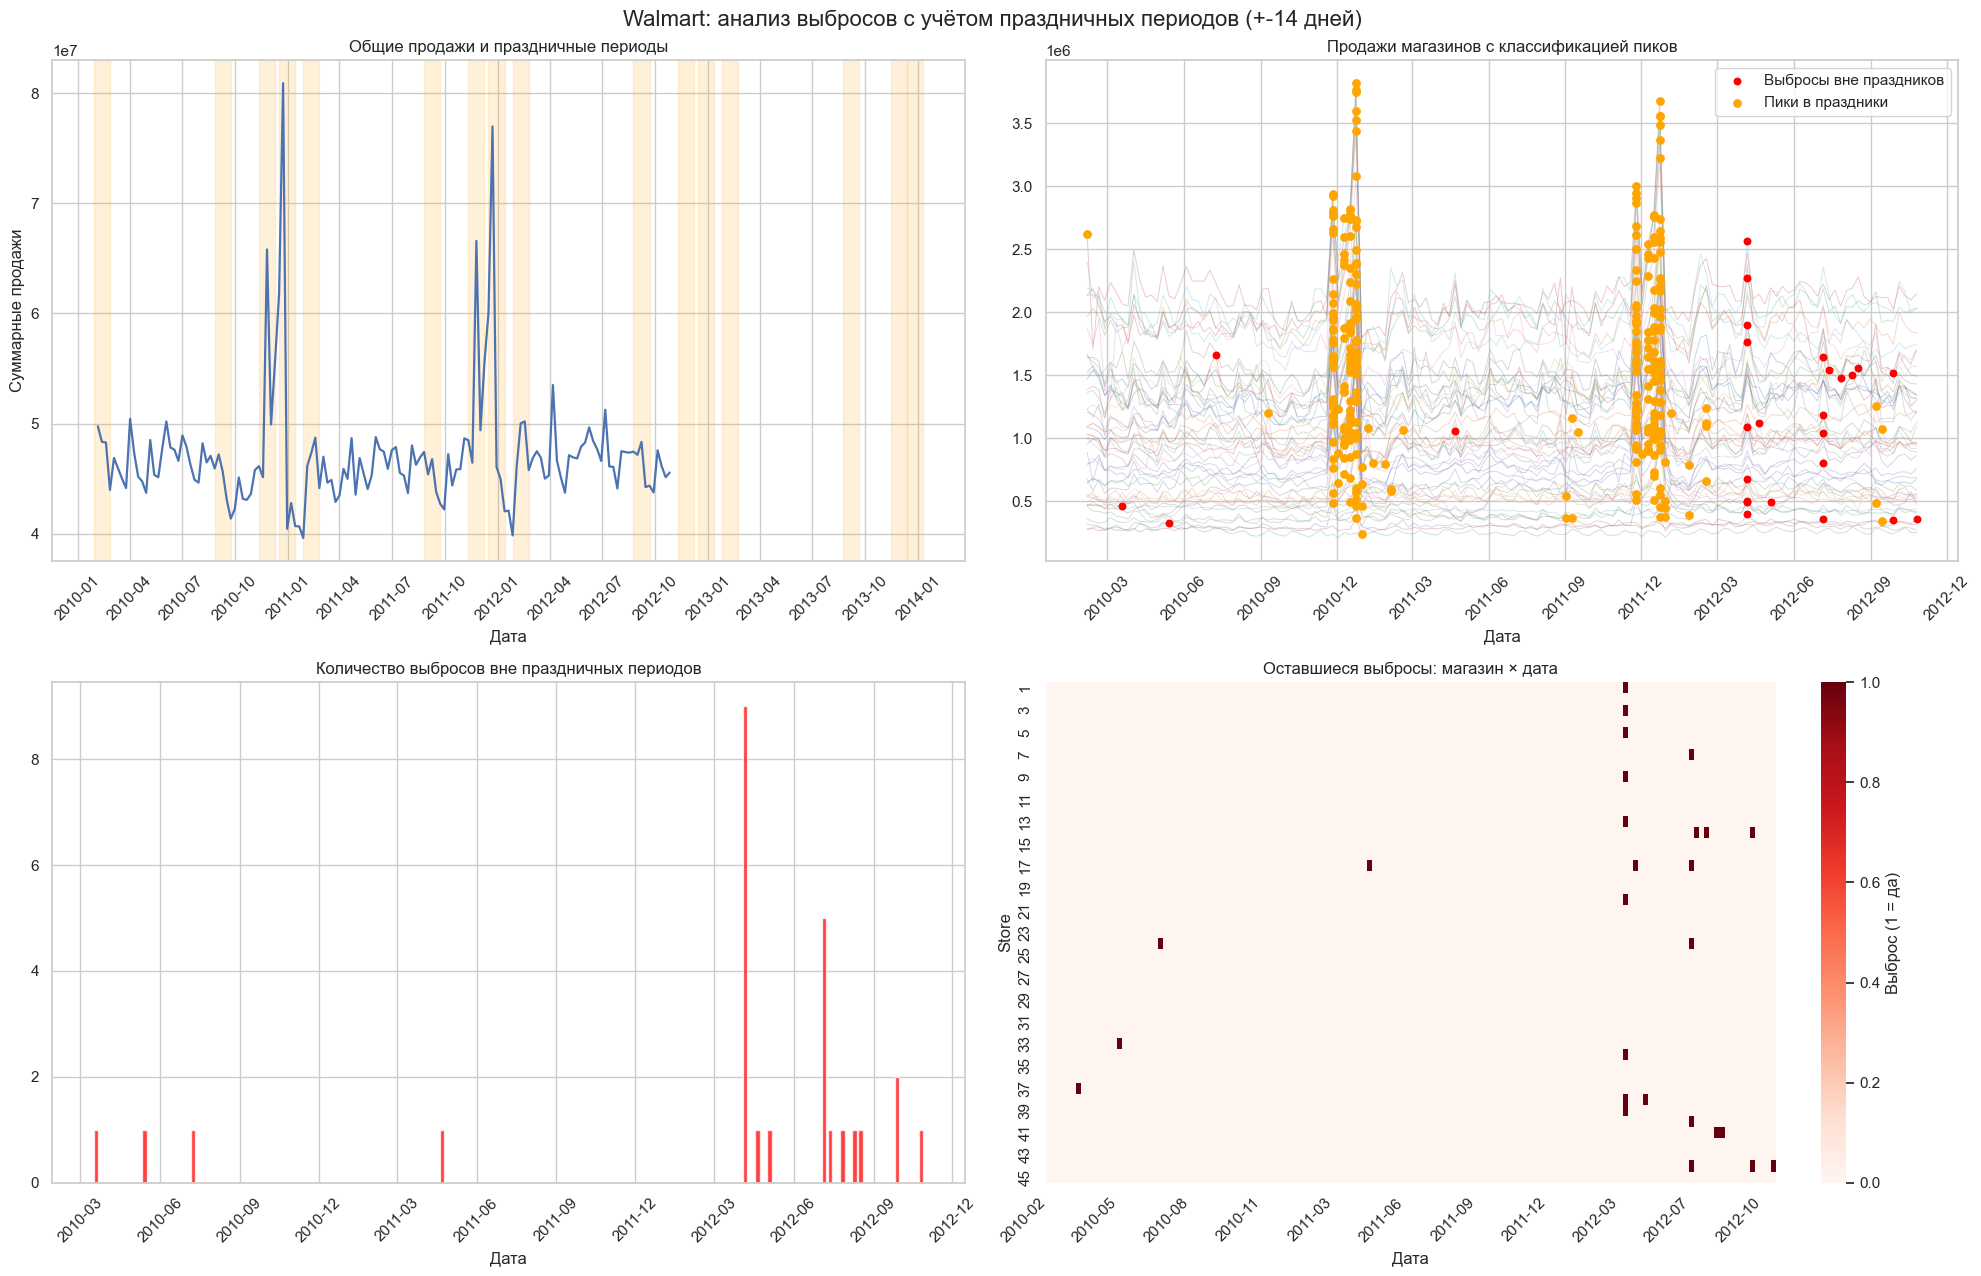

In [7]:
DAYS = 14

holiday_events = {
    'Super Bowl': ['12-Feb-10', '11-Feb-11', '10-Feb-12', '08-Feb-13'],
    'Labour Day': ['10-Sep-10', '09-Sep-11', '07-Sep-12', '06-Sep-13'],
    'Thanksgiving': ['26-Nov-10', '25-Nov-11', '23-Nov-12', '29-Nov-13'],
    'Christmas': ['31-Dec-10', '30-Dec-11', '28-Dec-12', '27-Dec-13']
}

holidays_df = pd.DataFrame([
    {'Holiday': h, 'Holiday_Date': pd.to_datetime(d, format='%d-%b-%y')}
    for h, dates in holiday_events.items() for d in dates
])


df_check['Holiday_Period'] = False
df_check['Nearest_Holiday'] = None
df_check['Days_To_Holiday'] = np.nan

for _, row in holidays_df.iterrows():
    delta = (row['Holiday_Date'] - df_check['Date']).dt.days
    mask = delta.abs() <= DAYS

    # Обновляем, если это первый подходящий праздник или он ближе текущего
    update_mask = mask & (df_check['Days_To_Holiday'].isna() | (delta < df_check['Days_To_Holiday']))

    df_check.loc[mask, 'Holiday_Period'] = True
    df_check.loc[update_mask, 'Nearest_Holiday'] = row['Holiday']
    df_check.loc[update_mask, 'Days_To_Holiday'] = delta

# 3. Классификация выбросов
df_check['Confirmed_IQR_Outlier'] = df_check['IQR_Outlier'] & ~df_check['Holiday_Period']
df_check['Holiday_Peak'] = df_check['IQR_Outlier'] & df_check['Holiday_Period']

print(f"Наблюдений в праздничных периодах: {df_check['Holiday_Period'].sum()}")
print(f"Выбросов всего: {df_check['IQR_Outlier'].sum()}")
print(f"Выбросов в праздничных периодах: {df_check['Holiday_Peak'].sum()}")
print(f"Обычные потенциальные выбросы: {df_check['Confirmed_IQR_Outlier'].sum()}")
print(f"Праздничные пики, исключённые из выбросов: {df_check['Holiday_Peak'].sum()}\n")


sns.set_theme(style='whitegrid')

fig, axes = plt.subplots(2, 2, figsize=(20, 13))
ax1, ax2, ax3, ax4 = axes.flatten()

# График 1: Общие продажи и праздничные периоды
total_sales = df_check.groupby('Date')['Weekly_Sales'].sum()
ax1.plot(total_sales.index, total_sales.values, linewidth=1.6)

for _, h in holidays_df.iterrows():
     ax1.axvspan(h['Holiday_Date'] - pd.Timedelta(days=DAYS), h['Holiday_Date'] + pd.Timedelta(days=DAYS), alpha=0.15, color='orange')

ax1.set_title('Общие продажи и праздничные периоды')
ax1.set_ylabel('Суммарные продажи')

# График 2: Все магазины и классификация выбросов
for _, group in df_check.groupby('Store'):
    ax2.plot(group['Date'], group['Weekly_Sales'], linewidth=0.7, alpha=0.3)

ordinary = df_check[df_check['Confirmed_IQR_Outlier']]
holiday_peaks = df_check[df_check['Holiday_Peak']]

ax2.scatter(ordinary['Date'], ordinary['Weekly_Sales'], color='red', s=22, label='Выбросы вне праздников', zorder=4)
ax2.scatter(holiday_peaks['Date'], holiday_peaks['Weekly_Sales'], color='orange', s=28, label='Пики в праздники', zorder=5)

ax2.set_title('Продажи магазинов с классификацией пиков')
ax2.legend()

# График 3: Число выбросов по датам (вне праздников)
ordinary_by_date = ordinary.groupby('Date')['Store'].nunique()
ax3.bar(ordinary_by_date.index, ordinary_by_date.values, width=5, color='red', alpha=0.75)
ax3.set_title('Количество выбросов вне праздничных периодов')

# График 4: Тепловая карта оставшихся выбросов
heatmap_data = df_check.pivot_table(
    index='Store', columns='Date', values='Confirmed_IQR_Outlier', aggfunc='max', fill_value=0
).astype(int)

sns.heatmap(heatmap_data, cmap='Reds', cbar_kws={'label': 'Выброс (1 = да)'}, ax=ax4)
ax4.set_title('Оставшиеся выбросы: магазин × дата')

# Унифицированное форматирование осей для всех графиков
for ax in (ax1, ax2, ax3, ax4):
    ax.set_xlabel('Дата')
    if ax != ax4:
        ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
        ax.tick_params(axis='x', rotation=45)
    else:
        # Для heatmap
        step = max(1, len(heatmap_data.columns) // 10)
        ticks = np.arange(0, len(heatmap_data.columns), step)
        ax.set_xticks(ticks + 0.5)
        ax.set_xticklabels([heatmap_data.columns[i].strftime('%Y-%m') for i in ticks], rotation=45, ha='right')

fig.suptitle('Walmart: анализ выбросов с учётом праздничных периодов (+-14 дней)', fontsize=16)
fig.tight_layout()
plt.show()

In [8]:
df_clean = df_check.loc[
    ~df_check['Confirmed_IQR_Outlier']
].copy()

df_clean.drop(
    columns=[
        'Lower', 'Upper',
        'IQR_Outlier', 'Outlier_Type',
        'Confirmed_IQR_Outlier', 'Holiday_Peak',
        'Holiday_Period', 'Nearest_Holiday',
        'Days_To_Holiday'
    ],
    errors='ignore',
    inplace=True
)

print('До обработки:', len(df_check))
print('После обработки:', len(df_clean))
print('Удалено строк:', len(df_check) - len(df_clean))

До обработки: 6435
После обработки: 6408
Удалено строк: 27


Проектирование признаков

In [9]:
# Даты
df_clean["Year"] = df_clean["Date"].dt.year.astype("int16")

df_clean["Quarter_Sin"] = np.sin(2 * np.pi * df_clean["Date"].dt.quarter / 4)
df_clean["Quarter_Cos"] = np.cos(2 * np.pi * df_clean["Date"].dt.quarter / 4)

month = df_clean["Date"].dt.month
df_clean["Month_Sin"] = np.sin(2 * np.pi * month / 12)
df_clean["Month_Cos"] = np.cos(2 * np.pi * month / 12)

iso = df_clean["Date"].dt.isocalendar()
week = iso.week.astype(float)
weeks_in_iso_year = iso.year.map(
    lambda y: pd.Timestamp(year=int(y), month=12, day=28).isocalendar().week
).astype(float)
df_clean["WeekOfYear_Sin"] = np.sin(2 * np.pi * week / weeks_in_iso_year)
df_clean["WeekOfYear_Cos"] = np.cos(2 * np.pi * week / weeks_in_iso_year)

# Конкретные праздники
holiday_dates = [
    '2010-02-12', '2011-02-11', '2012-02-10',  # Super Bowl
    '2010-09-10', '2011-09-09', '2012-09-07',  # Labour Day
    '2010-11-26', '2011-11-25', '2012-11-23',  # Thanksgiving
    '2010-12-31', '2011-12-30', '2012-12-28'   # Christmas
]
df_clean['IsSpecificHoliday'] = df_clean['Date'].isin(pd.to_datetime(holiday_dates)).astype('int8')

Лаггирование

In [10]:
df_clean = df_clean.sort_values(
    ["Store", "Date"]
).reset_index(drop=True)

grouped_sales = df_clean.groupby("Store")["Weekly_Sales"]

# Лаги
for k in [1, 2, 4, 13, 52]:
    df_clean[f"Sales_Lag_{k}"] = grouped_sales.shift(k)

# Скользящие средние и стандартные отклонения.
for w in [4, 13, 52]:
    df_clean[f"Sales_Roll_Mean_{w}"] = grouped_sales.transform(
        lambda s: s.shift(1).rolling(
            window=w,
            min_periods=w
        ).mean()
    )

    df_clean[f"Sales_Roll_Std_{w}"] = grouped_sales.transform(
        lambda s: s.shift(1).rolling(
            window=w,
            min_periods=w
        ).std()
    )

# Среднее всех доступных продаж до текущей недели
df_clean["Sales_Expanding_Mean"] = grouped_sales.transform(
    lambda s: s.shift(1).expanding(min_periods=1).mean()
)

# Отношение продаж прошлой недели к среднему за 4 прошлые недели
df_clean["Lag1_to_RollMean4"] = (
    df_clean["Sales_Lag_1"]
    / (df_clean["Sales_Roll_Mean_4"].abs() + 1e-6)
)


lag_roll_cols = [
    c for c in df_clean.columns
    if c.startswith("Sales_Lag_")
    or c.startswith("Sales_Roll_")
    or c in ["Sales_Expanding_Mean", "Lag1_to_RollMean4"]
]

display(
    df_clean[["Store", "Date", "Weekly_Sales"] + lag_roll_cols]
    .head(10)
)

print("Пропуски в лаговых и агрегатных признаках:")
print(df_clean[lag_roll_cols].isna().sum())

,Store,Date,Weekly_Sales,Sales_Lag_1,Sales_Lag_2,Sales_Lag_4,Sales_Lag_13,Sales_Lag_52,Sales_Roll_Mean_4,Sales_Roll_Std_4,Sales_Roll_Mean_13,Sales_Roll_Std_13,Sales_Roll_Mean_52,Sales_Roll_Std_52,Sales_Expanding_Mean,Lag1_to_RollMean4
0,1,2010-02-05,1643690.90,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,2010-02-12,1641957.44,1643690.90,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.643691e+06,NaN
2,1,2010-02-19,1611968.17,1641957.44,1643690.90,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.642824e+06,NaN
3,1,2010-02-26,1409727.59,1611968.17,1641957.44,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.632539e+06,NaN
4,1,2010-03-05,1554806.68,1409727.59,1611968.17,1643690.90,NaN,NaN,1.576836e+06,112353.415114,NaN,NaN,NaN,NaN,1.576836e+06,0.894023
5,1,2010-03-12,1439541.59,1554806.68,1409727.59,1641957.44,NaN,NaN,1.554615e+06,103135.002548,NaN,NaN,NaN,NaN,1.572430e+06,1.000123
6,1,2010-03-19,1472515.79,1439541.59,1554806.68,1611968.17,NaN,NaN,1.504011e+06,95360.050839,NaN,NaN,NaN,NaN,1.550282e+06,0.957135
7,1,2010-03-26,1404429.92,1472515.79,1439541.59,1409727.59,NaN,NaN,1.469148e+06,62599.457150,NaN,NaN,NaN,NaN,1.539173e+06,1.002292
8,1,2010-04-02,1594968.28,1404429.92,1472515.79,1554806.68,NaN,NaN,1.467823e+06,64308.381016,NaN,NaN,NaN,NaN,1.522330e+06,0.956811
9,1,2010-04-09,1545418.53,1594968.28,1404429.92,1439541.59,NaN,NaN,1.477864e+06,82871.762296,NaN,NaN,NaN,NaN,1.530401e+06,1.079239


Пропуски в лаговых и агрегатных признаках:
Sales_Lag_1               45
Sales_Lag_2               90
Sales_Lag_4              180
Sales_Lag_13             585
Sales_Lag_52            2340
Sales_Roll_Mean_4        180
Sales_Roll_Std_4         180
Sales_Roll_Mean_13       585
Sales_Roll_Std_13        585
Sales_Roll_Mean_52      2340
Sales_Roll_Std_52       2340
Sales_Expanding_Mean      45
Lag1_to_RollMean4        180
dtype: int64


In [11]:
# Так как созданные строки заполнить не из чего, удаляем их
history_cols = [
    c for c in df_clean.columns
    if c.startswith("Sales_Lag_")
    or c.startswith("Sales_Roll_")
    or c in ["Sales_Expanding_Mean", "Lag1_to_RollMean4"]
]

rows_before = len(df_clean)

df_model = df_clean.dropna(subset=history_cols).copy()

print("Строк до очистки:", rows_before)
print("Строк после очистки:", len(df_model))
print("Удалено строк:", rows_before - len(df_model))
print("Осталось пропусков в признаках истории:",
      df_model[history_cols].isna().sum().sum())

Строк до очистки: 6408
Строк после очистки: 4068
Удалено строк: 2340
Осталось пропусков в признаках истории: 0


Разделение таблиц

In [12]:
target = "Weekly_Sales"
drop_for_X = ["Date", target]
feature_df = df_model.drop(columns=drop_for_X)

train = df_model[df_model["Date"] < cutoff_date].copy()
test = df_model[df_model["Date"] >= cutoff_date].copy()

# Строки, удалённые как выбросы, отсутствуют; все созданные лаги используют только прошлые строки
X_train = train.drop(columns=["Date", target])
y_train = train[target].copy()
X_test = test.drop(columns=["Date", target])
y_test = test[target].copy()

# Store — категория. One-hot учим на train и выравниваем столбцы test.
X_train["Store"] = X_train["Store"].astype(str)
X_test["Store"] = X_test["Store"].astype(str)
X_train = pd.get_dummies(X_train, columns=["Store"], drop_first=False, dtype=int)
X_test = pd.get_dummies(X_test, columns=["Store"], drop_first=False, dtype=int)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (2777, 71) Test: (1291, 71)


Масштабирование числовых признаков

In [13]:
exclude_cols = {
    "Year",
    "Quarter_Sin",
    "Quarter_Cos",
    "Month_Sin",
    "Month_Cos",
    "WeekOfYear_Sin",
    "WeekOfYear_Cos"
}

binary_cols = [
    c for c in X_train.columns
    if set(X_train[c].dropna().unique()).issubset({0, 1})
]

scale_cols = [
    c for c in X_train.select_dtypes(include=np.number).columns
    if c not in exclude_cols and c not in binary_cols
]

scaler = RobustScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_test_scaled[scale_cols] = scaler.transform(X_test[scale_cols])

print("Масштабировано признаков:", len(scale_cols))
print("Масштабированные признаки:", scale_cols)

Масштабировано признаков: 17
Масштабированные признаки: ['Temperature', 'Fuel_Price', 'CPI', 'Unemployment', 'Sales_Lag_1', 'Sales_Lag_2', 'Sales_Lag_4', 'Sales_Lag_13', 'Sales_Lag_52', 'Sales_Roll_Mean_4', 'Sales_Roll_Std_4', 'Sales_Roll_Mean_13', 'Sales_Roll_Std_13', 'Sales_Roll_Mean_52', 'Sales_Roll_Std_52', 'Sales_Expanding_Mean', 'Lag1_to_RollMean4']


Проверка и сохранение

In [14]:
assert X_train_scaled.isna().sum().sum() == 0
assert X_test_scaled.isna().sum().sum() == 0
assert list(X_train_scaled.columns) == list(X_test_scaled.columns)

print("Train:", X_train_scaled.shape, "| Test:", X_test_scaled.shape)
print("Диапазон target train:", float(y_train.min()), "—", float(y_train.max()))
print("Диапазон target test:", float(y_test.min()), "—", float(y_test.max()))

# Сохраняем отдельно признаки/target и исходные версии без масштабирования для аудита.
X_train_scaled.to_csv("X_train_scaled.csv", index=False)
X_test_scaled.to_csv("X_test_scaled.csv", index=False)
y_train.to_csv("y_train.csv", index=False)
y_test.to_csv("y_test.csv", index=False)

Train: (2777, 71) | Test: (1291, 71)
Диапазон target train: 215359.21 — 3676388.98
Диапазон target test: 237129.81 — 2358055.3
